In [1]:
# ── 1. Imports & connection ────────────────────────────────────────
import pandas as pd, matplotlib.pyplot as plt, geopandas as gpd
from sqlalchemy import create_engine, text

ENG = create_engine("postgresql://markfinlay:@localhost:5432/osm")
print("✅ Connected")

✅ Connected


In [2]:
# ── 2. Completeness counts: UK + IE merged ────────────────────────
sql_counts = """
WITH base AS (
  SELECT
    (surface IS NOT NULL) AS has_surface
  FROM planet_osm_line
  WHERE lower(highway) IN ('path','footway','track')
)
SELECT COUNT(*)                               AS total_ways,
       SUM(CASE WHEN has_surface THEN 1 END)  AS tagged_ways
FROM   base;
"""
df_cnt = pd.read_sql(sql_counts, ENG)
df_cnt["pct_tagged"] = 100 * df_cnt.tagged_ways / df_cnt.total_ways
display(df_cnt)

,total_ways,tagged_ways,pct_tagged
0,2791418,837720,30.010554


In [3]:
sql_top15 = """
SELECT surface, COUNT(*) AS n
FROM planet_osm_line
WHERE lower(highway) IN ('path','footway','track')
  AND surface IS NOT NULL
GROUP BY surface
ORDER BY n DESC
LIMIT 15;
"""
df_top15 = pd.read_sql(sql_top15, ENG)
display(df_top15)

,surface,n
0,asphalt,296421
1,paved,77501
2,dirt,75690
3,paving_stones,74839
4,grass,71989
5,gravel,52696
6,ground,50365
7,unpaved,39513
8,concrete,35015
9,compacted,26543


In [4]:
latex_table = df_top15.to_latex(index=False, caption="Top-15 raw \\texttt{surface=*} values in UK+IE extract.",
                                label="tab:osm-surface-top15")
print(latex_table)

\begin{table}
\caption{Top-15 raw \texttt{surface=*} values in UK+IE extract.}
\label{tab:osm-surface-top15}
\begin{tabular}{lr}
\toprule
surface & n \\
\midrule
asphalt & 296421 \\
paved & 77501 \\
dirt & 75690 \\
paving_stones & 74839 \\
grass & 71989 \\
gravel & 52696 \\
ground & 50365 \\
unpaved & 39513 \\
concrete & 35015 \\
compacted & 26543 \\
wood & 9376 \\
fine_gravel & 6727 \\
sett & 2656 \\
sand & 2335 \\
earth & 2277 \\
\bottomrule
\end{tabular}
\end{table}



In [12]:
int(df_cnt['tagged_ways'])

/var/folders/7h/xqm6zc8x3z35m07r4f7gz22h0000gn/T/ipykernel_35082/2180627057.py:1: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  int(df_cnt['tagged_ways'])


837720

/var/folders/7h/xqm6zc8x3z35m07r4f7gz22h0000gn/T/ipykernel_35082/1815628289.py:7: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  total_ways = int(df_cnt['total_ways'])
/var/folders/7h/xqm6zc8x3z35m07r4f7gz22h0000gn/T/ipykernel_35082/1815628289.py:8: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  tagged_ways = int(df_cnt['tagged_ways'])


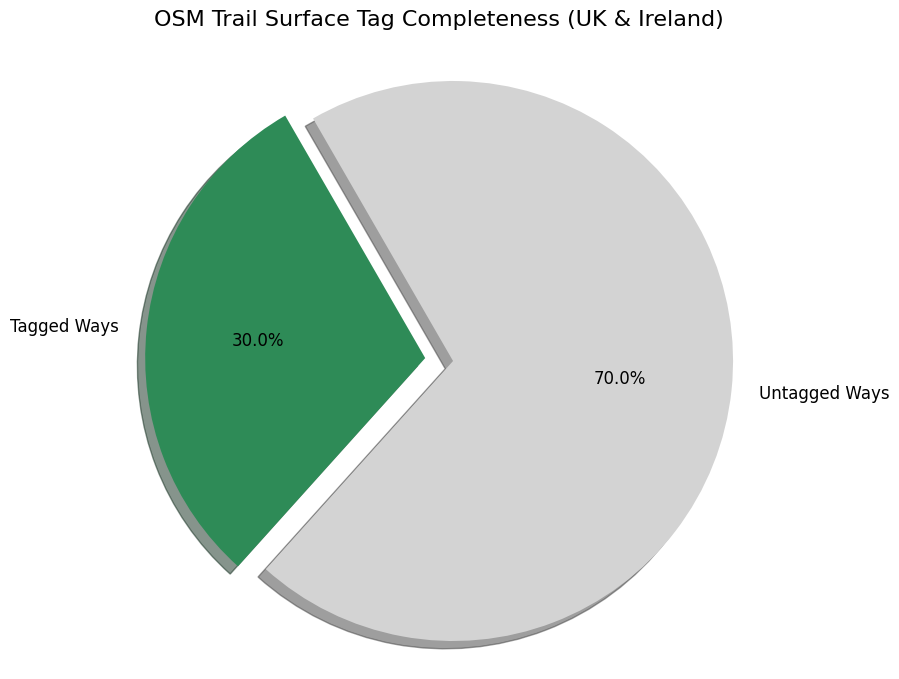

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. Simulate Data Based on Thesis Findings ---
# Your thesis states that ~30% of 2.79 million relevant ways are tagged.
# This simulation creates a DataFrame without needing a live database connection.
total_ways = int(df_cnt['total_ways'])
tagged_ways = int(df_cnt['tagged_ways'])
untagged_ways = total_ways - tagged_ways

# --- 2. Prepare Data for Plotting ---
labels = ['Tagged Ways', 'Untagged Ways']
sizes = [tagged_ways, untagged_ways]
# Using a color scheme to highlight the tagged portion
colors = ['#2E8B57', '#D3D3D3']  # SeaGreen and LightGray
explode = (0.1, 0)  # Explode the 'Tagged Ways' slice for emphasis

# --- 3. Render and Display the Pie Chart ---
plt.figure(figsize=(8, 8))
plt.pie(sizes,
        explode=explode,
        labels=labels,
        colors=colors,
        autopct='%1.1f%%', # Format percentages to one decimal place
        shadow=True,
        startangle=120,
        textprops={'fontsize': 12})

    plt.title('OSM Trail Surface Tag Completeness (UK & Ireland)', fontsize=16, pad=20)
plt.axis('equal')  # Ensures the pie is drawn as a circle.

    # In a Jupyter Notebook, this line will display the chart inline
plt.show()